In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import fsolve
from scipy.optimize import curve_fit
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
%matplotlib inline


## Data Reading

In [2]:
#reads in file as 
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 


In [3]:
print(repsData.columns)

Index(['NAME', 'PARTY', 'DISTRICT', 'DAYS CLAIMED', 'TOTAL'], dtype='str')


In [4]:
#reads in file using pandas, fixes some white space issue in the days claimed column i lost sleep over and spent WAYYYYYY too long on
#also probably a much better way exists but i kinda like that pandas uses the first row as a name for the columns and thats kinda convenient
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 
repsData.columns = repsData.columns.str.replace("\xa0", " ").str.strip()

#gets rid of the last row 
repsData = repsData.iloc[:-1]
#formats the total column to be just a float number 
repsData["TOTAL"] = repsData["TOTAL"].str.replace("$", "").str.replace(",", "").astype(float)

In [5]:
commiteeData = pd.read_excel('Wisconsin_Assembly_2025_26_Committee_and_Hometown_Data.xlsx')
commiteeData.head()

,Assembly District,Representative,Party,Hometown,Approx. Distance to Madison (miles),Committee Count,Committee Assignments
0,15,Adam Neylon,R,Pewaukee,65,5,"Energy & Utilities; Health, Aging & Long-Term ..."
1,39,Alex Dallman,R,Green Lake,85,1,Joint Committee on Finance
2,81,Alex Joers,D,Middleton,10,4,Colleges & Universities; Small Business Develo...
3,90,Amaad Rivera-Wagner,D,Green Bay,145,2,Consumer Protection; Local Government
4,32,Amanda Nedweski,R,Pleasant Prairie,105,2,Colleges & Universities; Government Operations...


## Data Manipulation

In [6]:
#Remove bottom row of repsData and turns district to an int
repsData = repsData.iloc[:-1]
repsData['DISTRICT'] = repsData['DISTRICT'].astype(int)

#Sorts based on district
repsData = repsData.sort_values(by='DISTRICT')
commiteeData =commiteeData.sort_values(by='Assembly District')

#Consolidates usable to data to one dataframe
repsData['DISTANCE'] = commiteeData['Approx. Distance to Madison (miles)']
repsData['COMMITTEE_COUNT'] = commiteeData['Committee Count']
repsData = repsData.rename(columns={'DAYS CLAIMED':'DAYS_CLAIMED'})
repsData['COMMITTEE_ASSIGNMENTS'] = commiteeData['Committee Assignments']

#Adding Per Diem/Day Column
repsData['PER_DIEM/DAY'] = round(repsData['TOTAL'] / repsData['DAYS_CLAIMED'], 2)

repsData.head(100)

,NAME,PARTY,DISTRICT,DAYS_CLAIMED,TOTAL,DISTANCE,COMMITTEE_COUNT,COMMITTEE_ASSIGNMENTS,PER_DIEM/DAY
16,"Kitchens, Joel",R,1,113.0,15903.0,170,4,Consumer Protection; Energy & Utilities; Fores...,140.73
20,"Sortwell, Shae",R,2,113.0,15358.0,60,4,"Constitution & Ethics; Forestry, Parks & Outdo...",135.91
22,"Steffen, David",R,4,106.0,14845.0,125,5,Agriculture; Colleges & Universities; Forestry...,140.05
18,"Goeben, Joy",R,5,114.0,15475.5,160,2,Education; Public Benefit Reform,135.75
87,"Behnke, Elijah",R,6,66.0,7150.0,145,4,Commerce; Criminal Justice & Public Safety; Fi...,108.33
...,...,...,...,...,...,...,...,...,...
73,"Billings, Jill",D,95,74.0,9107.0,90,3,Financial Institutions; State Affairs; Joint L...,123.07
41,"Johnson, Tara",D,96,92.0,12280.0,55,6,Colleges & Universities; Criminal Justice & Pu...,133.48
88,"Duchow, Cindi",R,97,72.0,7150.0,80,3,Energy & Utilities; Jobs & Economy; Regulatory...,99.31
72,"Piwowarczyk, Jim",R,98,86.0,9202.0,90,5,"Corrections; Health, Aging & Long-Term Care; H...",107.00


In [7]:
# Normalize spacing around the semicolons, then one-hot encode
committee_dummies = (
    repsData["COMMITTEE_ASSIGNMENTS"]
    .str.replace(r"\s*;\s*", ";", regex=True)
    .str.strip()
    .str.get_dummies(sep=";")
)

# Get the committee names in an array
committee_names = sorted({c.strip() for c in repsData["COMMITTEE_ASSIGNMENTS"].str.split(";").explode().dropna()})

# Combine Data
repsData = pd.concat([repsData, committee_dummies], axis=1)
repsData = repsData.drop(columns="COMMITTEE_ASSIGNMENTS")

repsData.columns = repsData.columns.str.replace(" ", "_")

In [8]:
committee_names = np.array(committee_names)

committee_names = np.char.replace(committee_names.astype(str), " ", "_")

print(committee_names)

['Agriculture' 'Assembly_Committee_on_Assembly_Organization'
 'Campaigns_&_Elections' 'Children_&_Families' 'Colleges_&_Universities'
 'Commerce' 'Constitution_&_Ethics' 'Consumer_Protection' 'Corrections'
 'Criminal_Justice_&_Public_Safety' 'Education' 'Energy_&_Utilities'
 'Environment' 'Financial_Institutions'
 'Forestry,_Parks_&_Outdoor_Recreation'
 'Government_Operations,_Accountability_&_Transparency'
 'Health,_Aging_&_Long-Term_Care' 'Housing_&_Real_Estate' 'Insurance'
 'Jobs_&_Economy' 'Joint_Committee_for_Review_of_Administrative_Rules'
 'Joint_Committee_on_Employment_Relations' 'Joint_Committee_on_Finance'
 'Joint_Committee_on_Information_Policy_&_Technology'
 'Joint_Committee_on_Legislative_Organization' 'Joint_Legislative_Audit'
 'Joint_Legislative_Council'
 'Joint_Review_Committee_on_Criminal_Penalties'
 'Joint_Survey_Committee_on_Retirement_Systems'
 'Joint_Survey_Committee_on_Tax_Exemptions' 'Judiciary' 'LawRevision'
 'Local_Government' 'Mental_Health_&_Substance_Abuse_P

In [9]:
#Turns all columns into numpy arrays

districtReps = repsData["DISTRICT"].astype(int).to_numpy()
daysClaimed = repsData["DAYS_CLAIMED"].astype(int).to_numpy()
perDiem = repsData["TOTAL"].astype(int).to_numpy()
distance = repsData["DISTANCE"].astype(int).to_numpy()
committeeCount = repsData["COMMITTEE_COUNT"].astype(int).to_numpy()

perDiemDay = repsData["PER_DIEM/DAY"].astype(int).to_numpy()

## Party Averages

In [10]:
print('COMMITTEE COUNT AVERAGES')
print()

cCount = sum(repsData['COMMITTEE_COUNT'])/len(repsData)
print(F"Average: {cCount}")

party_averages = repsData.groupby('PARTY')['COMMITTEE_COUNT'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

COMMITTEE COUNT AVERAGES

Average: 3.979381443298969
Republican Average : 3.7735849056603774
Democrat Average:   4.2272727272727275


In [11]:
print('DISTANCE AVERAGES')
print()

dAVG = sum(repsData['DISTANCE'])/len(repsData)
print(F"Average: {dAVG}")

party_averages = repsData.groupby('PARTY')['DISTANCE'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

DISTANCE AVERAGES

Average: 98.55670103092784
Republican Average : 87.64150943396227
Democrat Average:   111.70454545454545


In [12]:
print('DAYS CLAIMED AVERAGES')
print()

daysAVG = sum(repsData['DAYS_CLAIMED'])/len(repsData)
print(F"Average: {daysAVG}")

party_averages = repsData.groupby('PARTY')['DAYS_CLAIMED'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

DAYS CLAIMED AVERAGES

Average: 103.03092783505154
Republican Average : 98.83018867924528
Democrat Average:   108.0909090909091


In [13]:
print('PER DIEM AVERAGES')
print()

totalAVG = sum(repsData['TOTAL'])/len(repsData)
print(F"Average: {totalAVG}")

party_averages = repsData.groupby('PARTY')['TOTAL'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

PER DIEM AVERAGES

Average: 11974.69587628866
Republican Average : 12303.811320754718
Democrat Average:   11578.261363636364


In [14]:
print('PER DIEM / DAY AVERAGES')
print()

pddAVG = sum(repsData['PER_DIEM/DAY'])/len(repsData)
print(F"Average: {pddAVG}")

party_averages = round(repsData.groupby('PARTY')['PER_DIEM/DAY'].mean(), 2)

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

PER DIEM / DAY AVERAGES

Average: 116.51257731958762
Republican Average : 122.75
Democrat Average:   109.0


## Graphs and Such

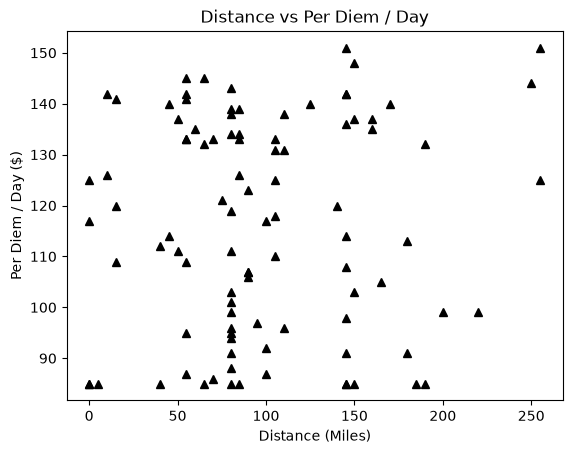

In [15]:
plt.title('Distance vs Per Diem / Day')
plt.xlabel('Distance (Miles)')
plt.ylabel('Per Diem / Day ($)')

plt.plot(distance, perDiemDay, 'k^');

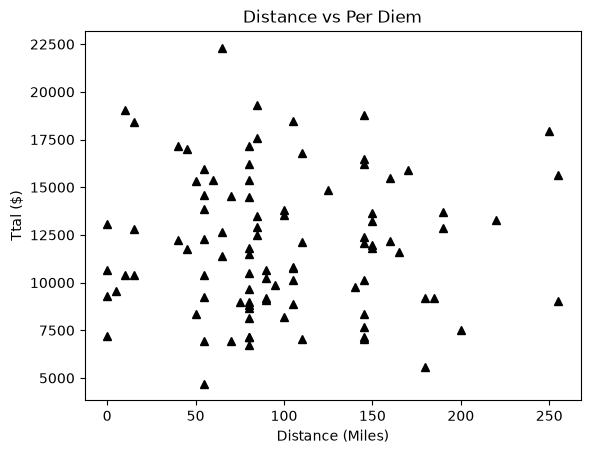

In [16]:
plt.title('Distance vs Per Diem')
plt.xlabel('Distance (Miles)')
plt.ylabel('Ttal ($)')

plt.plot(distance, perDiem, 'k^');

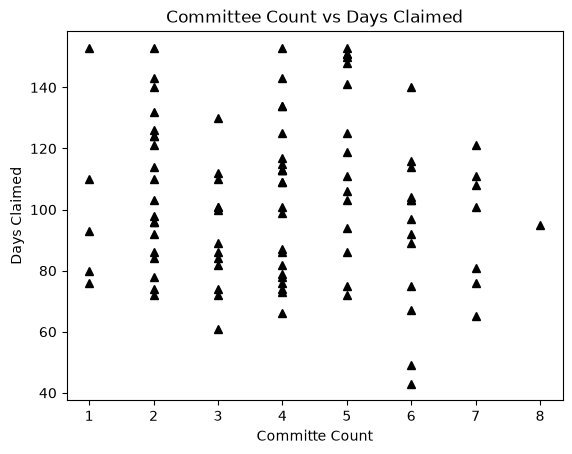

In [17]:
plt.title('Committee Count vs Days Claimed')
plt.xlabel('Committe Count')
plt.ylabel('Days Claimed')

plt.plot(committeeCount, daysClaimed, 'k^');

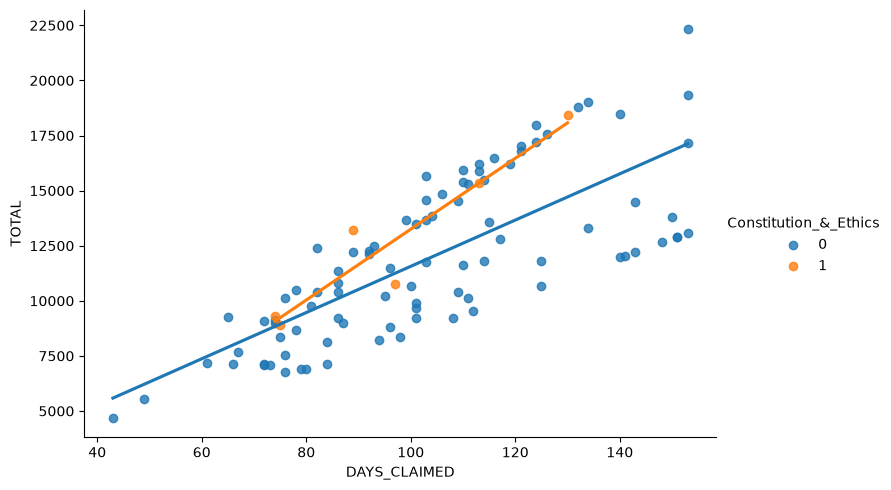

In [18]:
sns.lmplot(
    data=repsData,
    x="DAYS_CLAIMED",
    y="TOTAL",
    hue=committee_names[6], # You can get any of the Committees my changing the index
    ci=None,        
    height=5,
    aspect=1.5
)
#plt.title('TOTAL VS DAYS CLAIMED(With Party)')
plt.show()

In [19]:
#Multiple Linear Regression Model

formula = "DAYS_CLAIMED ~ DISTANCE + PARTY + " + " + ".join(f"Q('{c}')" for c in committee_names)

m = smf.ols(formula, data=repsData).fit()
print(m.params)

Intercept                                                    108.293349
PARTY[T.R]                                                   -11.192262
DISTANCE                                                      -0.022415
Q('Agriculture')                                              -4.772405
Q('Assembly_Committee_on_Assembly_Organization')             -15.678604
Q('Campaigns_&_Elections')                                    -3.200405
Q('Children_&_Families')                                     -10.575361
Q('Colleges_&_Universities')                                  31.485254
Q('Commerce')                                                -19.509185
Q('Constitution_&_Ethics')                                    -2.239447
Q('Consumer_Protection')                                       1.924113
Q('Corrections')                                             -12.563208
Q('Criminal_Justice_&_Public_Safety')                         -9.413107
Q('Education')                                                28

In [20]:
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:           DAYS_CLAIMED   R-squared:                       0.576
Model:                            OLS   Adj. R-squared:                  0.096
Method:                 Least Squares   F-statistic:                     1.199
Date:                Tue, 03 Nov 2026   Prob (F-statistic):              0.269
Time:                        13:25:22   Log-Likelihood:                -410.79
No. Observations:                  97   AIC:                             925.6
Df Residuals:                      45   BIC:                             1059.
Df Model:                          51                                         
Covariance Type:            nonrobust                                         
                                                                coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------